In [27]:
# Again Lets start with some imports...

from pathlib import Path

import geopandas as gpd
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.colors import Normalize

In [2]:
# Now to write paths to read in my data :)

Current_Path = Path.cwd()

Path_Root = Current_Path.parent.parent
Data_Path = Path_Root / "data" / "forecasting"
Forecast_Pop_File_Path = Data_Path / "SAP_Forecast_2136_Cleaned.csv"

Area_Path = Path_Root / "data" / "area_zones_data"
Area_File_Path = Area_Path / "Vic_Area_Zones.shp"

Forecast_Dwl_File_Path = Data_Path / "Household_Dwelling_Forecast_2136_CleanedV2.csv"

In [3]:
# Read in my data

Pop_Data = pd.read_csv(Forecast_Pop_File_Path)

Dwl_Data = pd.read_csv(Forecast_Dwl_File_Path)

Vic_Area_Zones = gpd.read_file(Area_File_Path)

In [6]:
Dwl_Data

,Unnamed: 0,GCCSA,SA4_Code,SA3_Code,SA2_Code,Region_Type,SA2_Name,Dwellings_2021,Dwellings_2026,Dwellings_2031,Dwellings_2036
0,0,2RVIC,201,20101,201011001,SA2,Alfredton,6245.0,8252.000000,9732.000000,10830.000000
1,1,2RVIC,201,20101,201011002,SA2,Ballarat,5970.0,6134.548371,6350.037451,6553.095884
2,2,2RVIC,201,20101,201011005,SA2,Buninyong,2768.0,2943.325691,3199.637967,3445.433425
3,3,2RVIC,201,20101,201011006,SA2,Delacombe,4172.0,6585.376102,8740.266903,10770.851234
4,4,2RVIC,201,20101,201011007,SA2,Smythes Creek,1490.0,1600.000000,1720.000000,1856.363636
...,...,...,...,...,...,...,...,...,...,...,...
517,517,2RVIC,217,21703,217031476,SA2,Otway,3993.0,4211.361160,4437.918335,4642.931909
518,518,2RVIC,217,21704,217041477,SA2,Moyne - East,3279.0,3434.000000,3581.886953,3753.941486
519,519,2RVIC,217,21704,217041478,SA2,Moyne - West,5119.0,5420.538505,5705.053233,5967.829190
520,520,2RVIC,217,21704,217041479,SA2,Warrnambool - North,9723.0,10423.000000,11179.442040,11979.578223


In [7]:
# Now to calc the dwelling growth percent from 2026 to 2036

Dwl_Data["Dwelling_Growth_Percent"] = (
    (
        Dwl_Data["Dwellings_2036"]
        - Dwl_Data["Dwellings_2026"]
    )
    / Dwl_Data["Dwellings_2026"]
) * 100

In [8]:
# Now to deal with NaN values

Dwl_Data.loc[
    Dwl_Data["Dwellings_2026"] == 0,
    "Dwelling_Growth_Percent"
] = np.nan

In [9]:
# Make sure these are same type!

Dwl_Data["SA2_Code"] = (
    Dwl_Data["SA2_Code"]
    .astype(str)
    .str.strip()
)

Vic_Area_Zones["SA2_CODE21"] = (
    Vic_Area_Zones["SA2_CODE21"]
    .astype(str)
    .str.strip()
)

In [10]:
Dwl_Map = Vic_Area_Zones.merge(
    Dwl_Data[
        [
            "SA2_Code",
            "Dwellings_2026",
            "Dwellings_2036",
            "Dwelling_Growth_Percent"
        ]
    ],
    left_on="SA2_CODE21",
    right_on="SA2_Code",
    how="left"
)

In [23]:
Dwl_Map["Dwelling_Growth_Percent"].describe()

count    518.000000
mean      16.664108
std       23.295083
min        0.000000
25%        6.433784
50%       10.583292
75%       17.819621
max      295.857988
Name: Dwelling_Growth_Percent, dtype: float64

In [24]:
Dwl_Map[
    [
        "SA2_NAME21",
        "Dwellings_2026",
        "Dwellings_2036",
        "Dwelling_Growth_Percent"
    ]
].sort_values(
    "Dwelling_Growth_Percent",
    ascending=False
).head(50)

,SA2_NAME21,Dwellings_2026,Dwellings_2036,Dwelling_Growth_Percent
130,Flemington Racecourse,338.000000,1338.000000,295.857988
147,Port Melbourne Industrial,5407.000000,17507.000000,223.783984
246,Wallan,12371.000000,30221.000000,144.289063
422,Rockbank - Mount Cottrell,13405.000000,29305.000000,118.612458
364,Clyde North - South,9779.000000,20504.000000,109.673791
430,Fraser Rise - Plumpton,8847.000000,17847.000000,101.729400
448,Tarneit - North,6415.000000,12915.000000,101.325019
357,Cranbourne South,10553.000000,20953.000000,98.550175
428,Cobblebank - Strathtulloh,4650.000000,9150.000000,96.774194
453,Wyndham Vale - North,5825.000000,11425.000000,96.137339


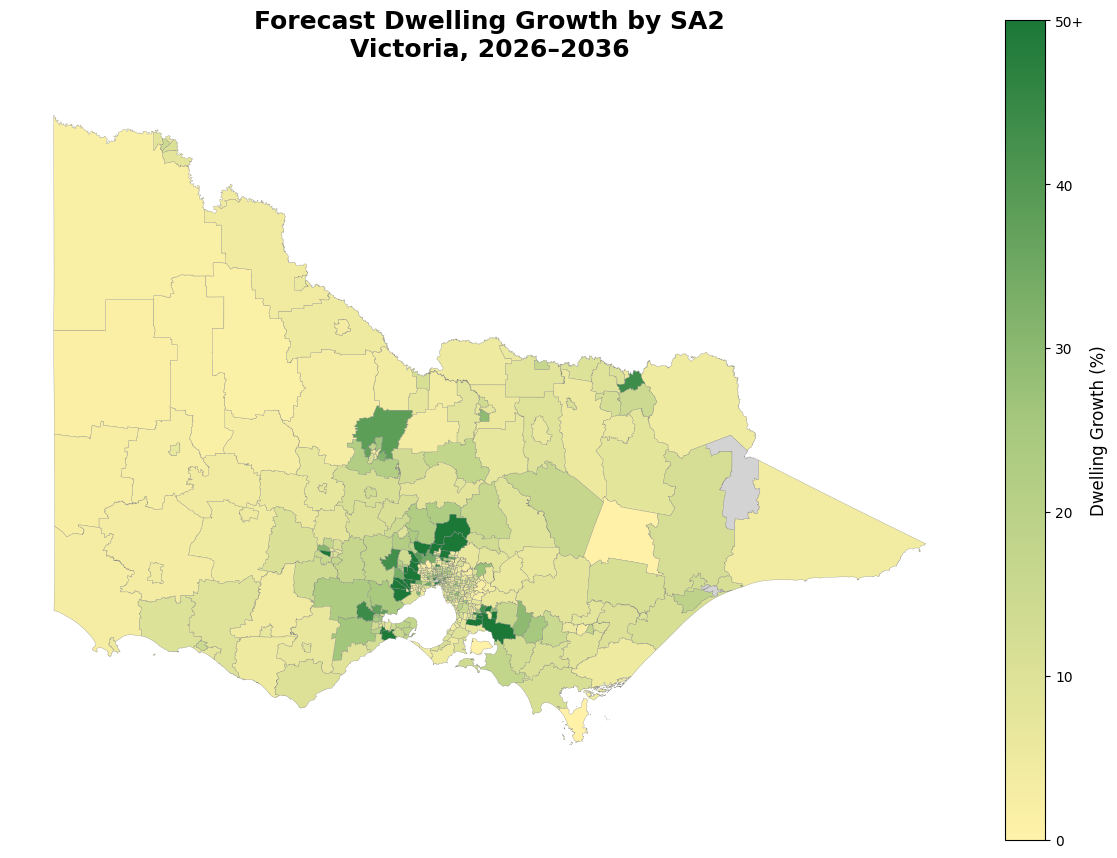

In [28]:

# Yellow -> Green colour map

Yellow_Green = LinearSegmentedColormap.from_list(
    "YellowGreen",
    [
        "#fff2a8",   # Yellow = little / no growth
        "#a8c97f",   # Light green = moderate growth
        "#1b7837"    # Dark green = high growth
    ]
)

# Cap visualisation at 50%

Dwl_Map["Dwelling_Growth_Plot"] = (
    Dwl_Map["Dwelling_Growth_Percent"]
    .clip(upper=50)
)


# Colour scale: 0% -> 50%+

norm = Normalize(
    vmin=0,
    vmax=50
)

fig, ax = plt.subplots(
    figsize=(12, 12)
)

# Plotting


Dwl_Map.plot(
    column="Dwelling_Growth_Plot",
    cmap=Yellow_Green,
    norm=norm,
    linewidth=0.2,
    edgecolor="grey",
    legend=False,
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    ax=ax
)

# Create colourbar manually


sm = mpl.cm.ScalarMappable(
    cmap=Yellow_Green,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.7,
    pad=0.03
)

cbar.set_label(
    "Dwelling Growth (%)",
    fontsize=12
)

# Colourbar ticks


ticks = [
    0,
    10,
    20,
    30,
    40,
    50
]

cbar.set_ticks(ticks)

cbar.set_ticklabels(
    [
        "0",
        "10",
        "20",
        "30",
        "40",
        "50+"
    ]
)

# Formatting


ax.set_title(
    "Forecast Dwelling Growth by SA2\n"
    "Victoria, 2026–2036",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()

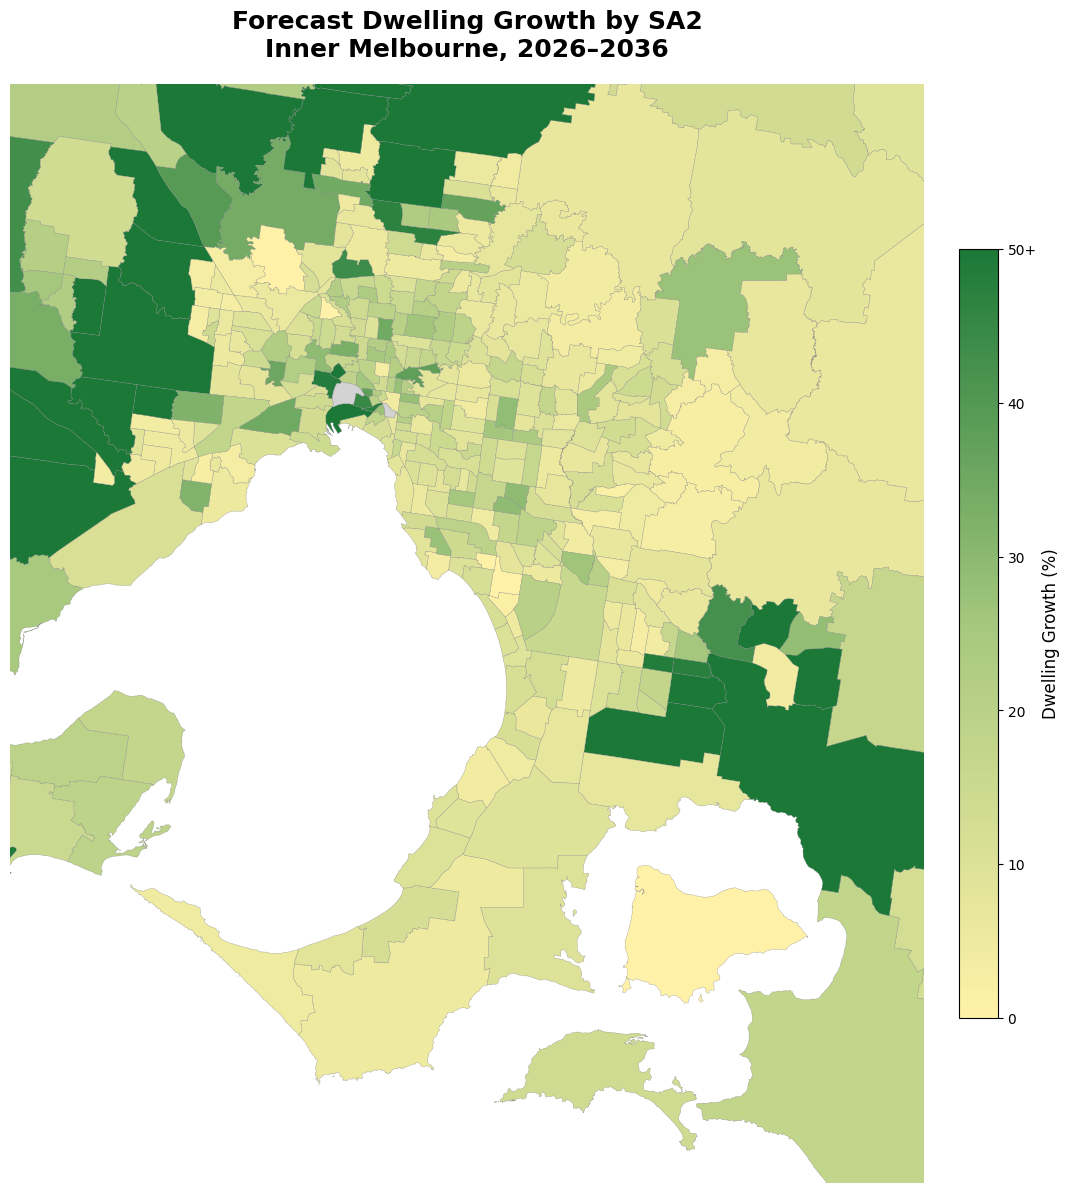

In [29]:
# Now for inner city melborune
# Yellow -> Green colour map

Yellow_Green = LinearSegmentedColormap.from_list(
    "YellowGreen",
    [
        "#fff2a8",   # Yellow = little / no growth
        "#a8c97f",   # Light green = moderate growth
        "#1b7837"    # Dark green = high growth
    ]
)

# Cap visualisation at 50%

Dwl_Map["Dwelling_Growth_Plot"] = (
    Dwl_Map["Dwelling_Growth_Percent"]
    .clip(upper=50)
)


# Colour scale: 0% -> 50%+

norm = Normalize(
    vmin=0,
    vmax=50
)

fig, ax = plt.subplots(
    figsize=(12, 12)
)

# Plotting


Dwl_Map.plot(
    column="Dwelling_Growth_Plot",
    cmap=Yellow_Green,
    norm=norm,
    linewidth=0.2,
    edgecolor="grey",
    legend=False,
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    ax=ax
)

# Create colourbar manually


sm = mpl.cm.ScalarMappable(
    cmap=Yellow_Green,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.7,
    pad=0.03
)

cbar.set_label(
    "Dwelling Growth (%)",
    fontsize=12
)

# Colourbar ticks


ticks = [
    0,
    10,
    20,
    30,
    40,
    50
]

cbar.set_ticks(ticks)

cbar.set_ticklabels(
    [
        "0",
        "10",
        "20",
        "30",
        "40",
        "50+"
    ]
)

# Zoom into Inner Melbourne
ax.set_xlim(144.50, 145.65)
ax.set_ylim(-38.60, -37.50)

# Formatting


ax.set_title(
    "Forecast Dwelling Growth by SA2\n"
    "Inner Melbourne, 2026–2036",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()